# Heatwave Tmax Sulawesi 1996–2025 — Combined Journal-Style Notebook

Notebook gabungan ini menyatukan alur yang sebelumnya tersebar di beberapa notebook: pembacaan **daily Tmax**, pembuatan mask Sulawesi, threshold kalender-harian **P90/P95** dengan **centered 15-day window**, uji sensitivitas **3/4/5 hari**, perhitungan **HWN, HWF, HWD, HWA, HWM**, dan plotting gaya jurnal internasional.

## Output plot utama
1. **Peta klimatologi daily Tmax rata-rata** 1996–2025.
2. **Perbandingan threshold P90 dan P95** + selisih P95−P90.
3. **Sensitivitas spasial** P90/P95 × minimum 3/4/5 hari (HWF).
4. **Sensitivitas time series** untuk HWN, HWF, HWD, HWA, HWM.
5. **Peta karakteristik heatwave** HWN, HWF, HWD, HWA, HWM.
6. **Time series karakteristik heatwave** Sulawesi dengan running mean dan tren Theil–Sen + Mann–Kendall.

## Definisi metodologis
- Default utama: **P90-D3** (`MAIN_SCENARIO = "P90_D3"`).
- Sensitivitas: **P90/P95 × D3/D4/D5**.
- Threshold dihitung untuk setiap hari kalender memakai data **±7 hari** dari seluruh tahun (total 15 hari × jumlah tahun).
- Event heatwave: `Tmax > threshold` selama sedikitnya `D` hari berturut-turut.
- **HWN** = jumlah kejadian heatwave per tahun.
- **HWF** = total hari heatwave per tahun.
- **HWD** = durasi maksimum kejadian heatwave per tahun.
- **HWA** = maksimum Tmax pada hari heatwave (default, mode absolut).
- **HWM** = rata-rata Tmax pada hari heatwave (default, mode absolut).
- Versi **excess above threshold** juga tetap dihitung dan disimpan sebagai `HWA_excess` dan `HWM_excess`.

Rujukan metode utama: Li (2020), *Science of the Total Environment* 721, 137664; Liu & Qin (2023), *International Journal of Biometeorology* 67, 2055–2068; Perkins & Alexander (2013), *Journal of Climate* 26, 4500–4517.


> **Visualisasi SMOOTH:** Figure 1, 2, 3, dan 5 memakai interpolasi linear khusus tampilan, clipping poligon Sulawesi, dan dukungan grid native. Angka pada grid, threshold, deteksi kejadian, indeks, dan tren tidak diubah. Set `DISPLAY_RENDER = "native"` untuk pemeriksaan resolusi asli.


## 0. Instalasi paket (jalankan hanya jika perlu)

Jika ada modul yang belum terpasang, jalankan di **Anaconda Prompt / CMD**, bukan harus di dalam notebook:

```bash
pip install numpy pandas matplotlib netCDF4 cartopy shapely scipy openpyxl
```

Cartopy dapat mengunduh data Natural Earth saat pertama kali dipakai. Setelah tersimpan di cache, pemakaian berikutnya biasanya tidak perlu mengunduh lagi.


In [1]:
# ============================================================
# 1. IMPORT + KONFIGURASI UTAMA
# ============================================================

from pathlib import Path
import re
import json
import gc
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from netCDF4 import Dataset, num2date

import cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader

from shapely.ops import unary_union
try:
    from shapely import contains_xy
except ImportError:
    from shapely import vectorized as _shapely_vectorized

from scipy.stats import theilslopes, kendalltau
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)

# ------------------------------------------------------------
# PATH — UBAH BAGIAN INI SAJA JIKA FOLDER BERBEDA
# ------------------------------------------------------------
TMAX_DIR = Path(r"D:\MERLI\data\T2M Max")
OUTPUT_DIR = Path(r"D:\MERLI\data\TMAX\HEATWAVE_JOURNAL_OUTPUT")

CACHE_DIR = OUTPUT_DIR / "cache"
RESULT_DIR = OUTPUT_DIR / "results"
PLOT_DIR = OUTPUT_DIR / "plots"

for folder in [OUTPUT_DIR, CACHE_DIR, RESULT_DIR, PLOT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# PERIODE DAN DEFINISI HEATWAVE
# ------------------------------------------------------------
START_YEAR = 1996
END_YEAR = 2025
YEARS = np.arange(START_YEAR, END_YEAR + 1, dtype=int)

WINDOW_DAYS = 15
PERCENTILES = [90, 95]
MIN_DURATIONS = [3, 4, 5]
SCENARIOS = [f"P{p}_D{d}" for p in PERCENTILES for d in MIN_DURATIONS]

# Definisi utama; sensitivity tetap menghitung semua skenario.
MAIN_SCENARIO = "P90_D3"

# HWA/HWM untuk figure utama:
# "absolute" -> HWA/HWM = Tmax aktual pada hari heatwave (sesuai Liu & Qin 2023)
# "excess"   -> HWA/HWM = exceedance di atas threshold (berguna untuk pembanding)
INTENSITY_MODE = "absolute"

# ------------------------------------------------------------
# CACHE / QC
# ------------------------------------------------------------
STRICT_COMPLETE_YEARS = True
REBUILD_DAILY_CACHE = False
REBUILD_THRESHOLDS = False
RECALCULATE_METRICS = False

# ------------------------------------------------------------
# PETA
# ------------------------------------------------------------
MAP_EXTENT = [118.0, 127.0, -7.0, 2.5]  # west, east, south, north
ROBUST_COLOR_LIMITS = True
SAVE_PDF = True
FIG_DPI = 400
# Tampilan halus mengikuti referensi UTCI Jawa: interpolasi visual saja.
DISPLAY_RENDER = "smooth"  # ubah ke "native" untuk melihat piksel grid 0.25°
DISPLAY_NX = 460
DISPLAY_NY = 490


# ------------------------------------------------------------
# STYLE JURNAL
# ------------------------------------------------------------
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "figure.titlesize": 14,
    "axes.linewidth": 0.8,
    "savefig.facecolor": "white",
    "figure.facecolor": "white",
})

if WINDOW_DAYS % 2 == 0:
    raise ValueError("WINDOW_DAYS harus ganjil. Untuk metode ini gunakan 15 hari.")

if MAIN_SCENARIO not in SCENARIOS:
    raise ValueError(f"MAIN_SCENARIO harus salah satu dari {SCENARIOS}")

if INTENSITY_MODE not in {"absolute", "excess"}:
    raise ValueError("INTENSITY_MODE harus 'absolute' atau 'excess'.")

print("TMAX directory :", TMAX_DIR)
print("Output         :", OUTPUT_DIR)
print("Periode        :", START_YEAR, "–", END_YEAR)
print("Main scenario  :", MAIN_SCENARIO)
print("Sensitivity    :", SCENARIOS)
print("Intensity mode :", INTENSITY_MODE)


TMAX directory : D:\MERLI\data\T2M Max
Output         : D:\MERLI\data\TMAX\HEATWAVE_JOURNAL_OUTPUT
Periode        : 1996 – 2025
Main scenario  : P90_D3
Sensitivity    : ['P90_D3', 'P90_D4', 'P90_D5', 'P95_D3', 'P95_D4', 'P95_D5']
Intensity mode : absolute


## 2. Fungsi pembacaan NetCDF

Fungsi di bawah dibuat toleran terhadap variasi nama koordinat (`latitude/lat`, `longitude/lon`), nama waktu (`time/valid_time`), dan variabel temperatur (`tmax`, `tasmax`, `t2m`, dll.). Data Kelvin otomatis dikonversi ke °C.


In [2]:
# ============================================================
# 2. FUNGSI BACA NETCDF
# ============================================================

def extract_year_from_filename(path):
    m = re.search(r"(19|20)\d{2}", Path(path).name)
    return int(m.group()) if m else None


def find_coordinate_variable(nc, kind):
    candidates = (
        ["latitude", "lat", "Latitude", "LAT"]
        if kind == "lat"
        else ["longitude", "lon", "Longitude", "LON"]
    )
    lower_map = {name.lower(): name for name in nc.variables}
    for candidate in candidates:
        if candidate.lower() in lower_map:
            return lower_map[candidate.lower()]

    for name, var in nc.variables.items():
        lname = name.lower()
        if kind == "lat" and "lat" in lname and var.ndim == 1:
            return name
        if kind == "lon" and ("lon" in lname or "long" in lname) and var.ndim == 1:
            return name
    raise KeyError(f"Variabel {kind} tidak ditemukan.")


def find_time_variable(nc):
    for candidate in ["time", "valid_time", "datetime", "date", "day", "days"]:
        if candidate in nc.variables:
            return candidate
    lower_map = {name.lower(): name for name in nc.variables}
    for candidate in ["time", "valid_time", "datetime", "date", "day", "days"]:
        if candidate.lower() in lower_map:
            return lower_map[candidate.lower()]
    return None


def find_tmax_variable(nc, lat_name, lon_name):
    preferred = [
        "tmax", "Tmax", "TX", "tx", "tasmax", "T2M_MAX", "t2m_max",
        "t2m", "2m_temperature"
    ]
    for name in preferred:
        if name in nc.variables and nc.variables[name].ndim == 3:
            return name

    lat_dim = nc.variables[lat_name].dimensions[0]
    lon_dim = nc.variables[lon_name].dimensions[0]
    candidates = []
    for name, var in nc.variables.items():
        if var.ndim == 3 and lat_dim in var.dimensions and lon_dim in var.dimensions:
            candidates.append(name)

    if len(candidates) == 1:
        return candidates[0]
    if len(candidates) > 1:
        for name in candidates:
            lname = name.lower()
            if "tmax" in lname or lname == "tx" or "tasmax" in lname:
                return name
        return candidates[0]
    raise KeyError("Variabel Tmax 3-D tidak ditemukan.")


def convert_to_celsius(arr, units=""):
    units_lower = str(units).strip().lower()
    arr = np.asarray(arr, dtype=np.float32)
    if units_lower in {"k", "kelvin", "degrees_k"} or "kelvin" in units_lower:
        return arr - np.float32(273.15)

    finite = arr[np.isfinite(arr)]
    # Fallback bila metadata unit buruk, tetapi nilai jelas Kelvin.
    if finite.size and float(np.nanmedian(finite)) > 100:
        return arr - np.float32(273.15)
    return arr


def decode_dates_from_time_variable(tvar):
    units = getattr(tvar, "units", None)
    calendar = getattr(tvar, "calendar", "standard")
    if units is None:
        raise ValueError("Variabel waktu tidak memiliki atribut units.")

    decoded = num2date(
        tvar[:], units=units, calendar=calendar,
        only_use_cftime_datetimes=False,
        only_use_python_datetimes=False,
    )
    dates = [pd.Timestamp(int(x.year), int(x.month), int(x.day)) for x in decoded]
    return pd.DatetimeIndex(dates)


def read_tmax_file(filepath, expected_year=None):
    filepath = Path(filepath)
    year = expected_year if expected_year is not None else extract_year_from_filename(filepath)

    with Dataset(filepath, "r") as nc:
        lat_name = find_coordinate_variable(nc, "lat")
        lon_name = find_coordinate_variable(nc, "lon")
        time_name = find_time_variable(nc)
        tmax_name = find_tmax_variable(nc, lat_name, lon_name)

        lat = np.asarray(nc.variables[lat_name][:], dtype=np.float64)
        lon = np.asarray(nc.variables[lon_name][:], dtype=np.float64)
        if lat.ndim != 1 or lon.ndim != 1:
            raise ValueError("Latitude dan longitude harus 1-D.")

        var = nc.variables[tmax_name]
        dims = list(var.dimensions)
        lat_dim = nc.variables[lat_name].dimensions[0]
        lon_dim = nc.variables[lon_name].dimensions[0]
        lat_axis = dims.index(lat_dim)
        lon_axis = dims.index(lon_dim)
        time_axes = [i for i in range(var.ndim) if i not in [lat_axis, lon_axis]]
        if len(time_axes) != 1:
            raise ValueError(f"Dimensi Tmax tidak dikenali: {dims}")
        time_axis = time_axes[0]

        raw = var[:]
        if np.ma.isMaskedArray(raw):
            raw = raw.filled(np.nan)
        arr = np.asarray(raw, dtype=np.float32)
        arr = np.moveaxis(arr, [time_axis, lat_axis, lon_axis], [0, 1, 2])
        units = getattr(var, "units", "")
        arr = convert_to_celsius(arr, units)

        if time_name is not None:
            dates = decode_dates_from_time_variable(nc.variables[time_name])
        else:
            if year is None:
                raise ValueError(f"Tidak ada time variable dan tahun tidak terbaca: {filepath.name}")
            ntime = arr.shape[0]
            expected_days = 366 if pd.Timestamp(year, 1, 1).is_leap_year else 365
            if ntime != expected_days:
                raise ValueError(
                    f"{filepath.name}: {ntime} record, tahun {year} seharusnya {expected_days} hari."
                )
            dates = pd.date_range(f"{year}-01-01", periods=ntime, freq="D")

        # Jika file masih sub-daily / tanggal duplikat, jadikan daily Tmax.
        if not dates.is_unique:
            unique_dates = pd.DatetimeIndex(sorted(dates.unique()))
            daily = np.full((len(unique_dates), arr.shape[1], arr.shape[2]), np.nan, np.float32)
            for i, day in enumerate(unique_dates):
                idx = np.where(dates == day)[0]
                daily[i] = np.nanmax(arr[idx], axis=0)
            arr = daily
            dates = unique_dates

    # Longitude -> -180..180 lalu grid diurutkan ascending.
    if np.nanmax(lon) > 180:
        lon = ((lon + 180) % 360) - 180

    lon_order = np.argsort(lon)
    lat_order = np.argsort(lat)
    lon = lon[lon_order]
    lat = lat[lat_order]
    arr = arr[:, lat_order, :][:, :, lon_order]

    return arr, dates, lat, lon, tmax_name, units


## 3. Scan 30 file dan QC periode

Notebook mengasumsikan satu file per tahun untuk 1996–2025. Tahun diutamakan dari nama file; bila nama file tidak memuat tahun, kode mencoba membaca tanggal pertama dari variabel waktu.


In [3]:
# ============================================================
# 3. SCAN FILE + QC TAHUN
# ============================================================

if not TMAX_DIR.exists():
    raise FileNotFoundError(f"Folder Tmax tidak ditemukan: {TMAX_DIR}")

all_nc_files = sorted(TMAX_DIR.glob("*.nc"))
if not all_nc_files:
    raise FileNotFoundError(f"Tidak ada file .nc di {TMAX_DIR}")


def detect_file_year(fp):
    y = extract_year_from_filename(fp)
    if y is not None:
        return y
    try:
        with Dataset(fp, "r") as nc:
            tname = find_time_variable(nc)
            if tname is not None:
                d = decode_dates_from_time_variable(nc.variables[tname])
                if len(d):
                    return int(d[0].year)
    except Exception:
        pass
    return None


year_to_file = {}
for fp in all_nc_files:
    year = detect_file_year(fp)
    if year is None or not (START_YEAR <= year <= END_YEAR):
        continue
    if year in year_to_file:
        raise RuntimeError(f"Lebih dari satu file terdeteksi untuk tahun {year}:\n{year_to_file[year]}\n{fp}")
    year_to_file[year] = fp

missing_years = [int(y) for y in YEARS if int(y) not in year_to_file]
found_years = sorted(year_to_file)

qc_files = pd.DataFrame([
    {"year": y, "file": year_to_file[y].name, "path": str(year_to_file[y])}
    for y in found_years
])

display(qc_files)
print("Tahun hilang:", missing_years)

if STRICT_COMPLETE_YEARS and missing_years:
    raise FileNotFoundError(f"Data Tmax tidak lengkap. Tahun hilang: {missing_years}")
if not found_years:
    raise FileNotFoundError("Tidak ada file Tmax yang cocok dengan periode penelitian.")

qc_files.to_csv(RESULT_DIR / "QC_input_files.csv", index=False)


,year,file,path
0,1996,tmax 1996.nc,D:\MERLI\data\T2M Max\tmax 1996.nc
1,1997,tmax 1997.nc,D:\MERLI\data\T2M Max\tmax 1997.nc
2,1998,tmax 1998.nc,D:\MERLI\data\T2M Max\tmax 1998.nc
3,1999,tmax 1999.nc,D:\MERLI\data\T2M Max\tmax 1999.nc
4,2000,tmax 2000.nc,D:\MERLI\data\T2M Max\tmax 2000.nc
5,2001,tmax 2001.nc,D:\MERLI\data\T2M Max\tmax 2001.nc
6,2002,tmax 2002.nc,D:\MERLI\data\T2M Max\tmax 2002.nc
7,2003,tmax 2003.nc,D:\MERLI\data\T2M Max\tmax 2003.nc
8,2004,tmax 2004.nc,D:\MERLI\data\T2M Max\tmax 2004.nc
9,2005,tmax 2005.nc,D:\MERLI\data\T2M Max\tmax 2005.nc


Tahun hilang: []


## 4. Baca grid dan bentuk mask Sulawesi

Mask dibentuk dari enam provinsi: Sulawesi Selatan, Tengah, Tenggara, Barat, Utara, dan Gorontalo. Batas provinsi juga dipakai sebagai overlay pada semua peta.


In [4]:
# ============================================================
# 4. INSPEKSI GRID + MASK SULAWESI
# ============================================================

first_year = found_years[0]
first_file = year_to_file[first_year]

test_data, test_dates, lat, lon, detected_var, detected_units = read_tmax_file(
    first_file, expected_year=first_year
)

print("File contoh :", first_file.name)
print("Variable    :", detected_var)
print("Units       :", detected_units)
print("Shape       :", test_data.shape)
print("Tanggal     :", test_dates.min(), "s.d.", test_dates.max())
print("Lat range   :", lat.min(), "to", lat.max(), "| n =", len(lat))
print("Lon range   :", lon.min(), "to", lon.max(), "| n =", len(lon))
print("Tmax range  :", float(np.nanmin(test_data)), "to", float(np.nanmax(test_data)), "°C")

del test_data
gc.collect()

# Natural Earth Admin-1
admin1_path = shpreader.natural_earth(
    resolution="10m",
    category="cultural",
    name="admin_1_states_provinces",
)
admin_records = list(shpreader.Reader(admin1_path).records())

province_targets = {
    "Sulawesi Selatan": ["South Sulawesi", "Sulawesi Selatan"],
    "Sulawesi Tengah": ["Central Sulawesi", "Sulawesi Tengah"],
    "Sulawesi Tenggara": ["Southeast Sulawesi", "Sulawesi Tenggara"],
    "Sulawesi Barat": ["West Sulawesi", "Sulawesi Barat"],
    "Sulawesi Utara": ["North Sulawesi", "Sulawesi Utara"],
    "Gorontalo": ["Gorontalo"],
}


def record_text(record):
    return " | ".join(str(v) for v in record.attributes.values() if v is not None)


province_geometries = {}
for province, aliases in province_targets.items():
    found = None
    for rec in admin_records:
        txt = record_text(rec)
        if "Indonesia" not in txt and "IDN" not in txt:
            continue
        if any(alias.lower() in txt.lower() for alias in aliases):
            found = rec.geometry
            break
    if found is not None:
        province_geometries[province] = found

if len(province_geometries) != 6:
    raise RuntimeError(
        "Tidak semua provinsi Sulawesi ditemukan di Natural Earth. "
        f"Yang ditemukan: {list(province_geometries)}"
    )

sulawesi_geometry = unary_union(list(province_geometries.values()))
lon2d, lat2d = np.meshgrid(lon, lat)

try:
    sulawesi_mask = contains_xy(sulawesi_geometry, lon2d, lat2d)
except NameError:
    sulawesi_mask = _shapely_vectorized.contains(sulawesi_geometry, lon2d, lat2d)

sulawesi_mask = np.asarray(sulawesi_mask, dtype=bool)

province_masks = {}
for province, geometry in province_geometries.items():
    try:
        m = contains_xy(geometry, lon2d, lat2d)
    except NameError:
        m = _shapely_vectorized.contains(geometry, lon2d, lat2d)
    province_masks[province] = np.asarray(m, dtype=bool)

if sulawesi_mask.sum() == 0:
    raise RuntimeError("Mask Sulawesi kosong. Cek domain data dan MAP_EXTENT.")

print("Grid total    :", sulawesi_mask.size)
print("Grid Sulawesi :", int(sulawesi_mask.sum()))
for province, m in province_masks.items():
    print(f"{province:20s}: {int(m.sum())} grid")


File contoh : tmax 1996.nc
Variable    : t2m
Units       : K
Shape       : (366, 57, 45)
Tanggal     : 1996-01-01 00:00:00 s.d. 1996-12-31 00:00:00
Lat range   : -7.0 to 7.0 | n = 57
Lon range   : 116.0 to 127.0 | n = 45
Tmax range  : 17.054595947265625 to 36.172027587890625 °C
Grid total    : 2565
Grid Sulawesi : 242
Sulawesi Selatan    : 65 grid
Sulawesi Tengah     : 77 grid
Sulawesi Tenggara   : 43 grid
Sulawesi Barat      : 21 grid
Sulawesi Utara      : 19 grid
Gorontalo           : 17 grid


## 5. Bangun cache daily Tmax 1996–2025

Cache `memmap` menghindari kernel jebol gara-gara semua tahun dipaksa nongkrong di RAM sekaligus. Kalau data input berubah, set `REBUILD_DAILY_CACHE = True` di bagian konfigurasi.


In [5]:
# ============================================================
# 5. DAILY TMAX CACHE
# ============================================================

expected_dates = pd.date_range(
    f"{START_YEAR}-01-01", f"{END_YEAR}-12-31", freq="D"
).to_numpy(dtype="datetime64[D]")

n_total_days = len(expected_dates)
nlat, nlon = len(lat), len(lon)
expected_shape = (n_total_days, nlat, nlon)

cache_tag = f"{START_YEAR}_{END_YEAR}"
daily_cache_path = CACHE_DIR / f"daily_tmax_{cache_tag}.dat"
dates_cache_path = CACHE_DIR / f"daily_dates_{cache_tag}.npy"
meta_cache_path = CACHE_DIR / f"daily_metadata_{cache_tag}.json"

cache_valid = False
if daily_cache_path.exists() and dates_cache_path.exists() and meta_cache_path.exists() and not REBUILD_DAILY_CACHE:
    try:
        meta = json.loads(meta_cache_path.read_text(encoding="utf-8"))
        cache_valid = (
            tuple(meta["shape"]) == expected_shape
            and meta["dtype"] == "float32"
            and meta.get("period") == [START_YEAR, END_YEAR]
        )
    except Exception:
        cache_valid = False

if cache_valid:
    print("Memakai cache daily Tmax:", daily_cache_path)
    daily_tmax = np.memmap(daily_cache_path, dtype=np.float32, mode="r+", shape=expected_shape)
    dates = np.load(dates_cache_path).astype("datetime64[D]")
else:
    print("Membangun cache daily Tmax...")
    daily_tmax = np.memmap(daily_cache_path, dtype=np.float32, mode="w+", shape=expected_shape)
    dates = expected_dates.copy()
    cursor = 0
    ref_lat = ref_lon = None

    for k, year in enumerate(YEARS, start=1):
        year = int(year)
        fp = year_to_file[year]
        arr, file_dates, file_lat, file_lon, _, _ = read_tmax_file(fp, expected_year=year)

        if ref_lat is None:
            ref_lat, ref_lon = file_lat.copy(), file_lon.copy()
        else:
            if not np.allclose(ref_lat, file_lat):
                raise ValueError(f"Latitude berubah pada {year}.")
            if not np.allclose(ref_lon, file_lon):
                raise ValueError(f"Longitude berubah pada {year}.")

        file_dates_np = file_dates.to_numpy(dtype="datetime64[D]")
        expected_slice = dates[cursor: cursor + len(file_dates_np)]
        if not np.array_equal(file_dates_np, expected_slice):
            raise ValueError(f"Kalender {year} tidak sesuai urutan harian yang diharapkan.")

        arr[:, ~sulawesi_mask] = np.nan
        daily_tmax[cursor: cursor + arr.shape[0]] = arr
        cursor += arr.shape[0]
        print(f"[{k:02d}/{len(YEARS):02d}] {year} | {arr.shape[0]} hari | {fp.name}")
        del arr
        gc.collect()

    if cursor != n_total_days:
        raise RuntimeError(f"Jumlah hari cache {cursor}, seharusnya {n_total_days}.")

    daily_tmax.flush()
    np.save(dates_cache_path, dates)
    meta_cache_path.write_text(json.dumps({
        "shape": list(expected_shape),
        "dtype": "float32",
        "period": [START_YEAR, END_YEAR],
        "variable": detected_var,
    }, indent=2), encoding="utf-8")

print("Daily Tmax shape:", daily_tmax.shape)
print("Periode         :", dates[0], "s.d.", dates[-1])
print("Cache size (MB) :", round(daily_cache_path.stat().st_size / 1024**2, 2))


Memakai cache daily Tmax: D:\MERLI\data\TMAX\HEATWAVE_JOURNAL_OUTPUT\cache\daily_tmax_1996_2025.dat
Daily Tmax shape: (10958, 57, 45)
Periode         : 1996-01-01 s.d. 2025-12-31
Cache size (MB) : 107.22


## 6. Fungsi visualisasi jurnal

Semua peta memakai extent yang sama, batas provinsi, coastline, panel label, serta colorbar yang konsisten. Rentang warna default memakai persentil 2–98 agar satu outlier nggak ngerusak seluruh peta kayak bocah nyenggol tripod.


In [6]:
# ============================================================
# 6. HELPER PLOTTING
# ============================================================

def robust_limits(arrays, low=2, high=98, symmetric=False):
    if not isinstance(arrays, (list, tuple)):
        arrays = [arrays]
    vals = []
    for a in arrays:
        a = np.asarray(a)
        f = a[np.isfinite(a)]
        if f.size:
            vals.append(f)
    if not vals:
        return (-1.0, 1.0) if symmetric else (0.0, 1.0)
    vals = np.concatenate(vals)
    if symmetric:
        vmax = float(np.nanpercentile(np.abs(vals), high))
        if not np.isfinite(vmax) or vmax == 0:
            vmax = float(np.nanmax(np.abs(vals))) if vals.size else 1.0
        return -vmax, vmax
    if ROBUST_COLOR_LIMITS:
        vmin = float(np.nanpercentile(vals, low))
        vmax = float(np.nanpercentile(vals, high))
    else:
        vmin, vmax = float(np.nanmin(vals)), float(np.nanmax(vals))
    if np.isclose(vmin, vmax):
        vmin, vmax = float(np.nanmin(vals)), float(np.nanmax(vals))
        if np.isclose(vmin, vmax):
            vmax = vmin + 1e-6
    return vmin, vmax


def setup_map_ax(ax, left_labels=True, bottom_labels=True):
    ax.set_extent(MAP_EXTENT, crs=ccrs.PlateCarree())
    ax.coastlines(resolution="10m", linewidth=0.6)
    for geom in province_geometries.values():
        ax.add_geometries(
            [geom], crs=ccrs.PlateCarree(), facecolor="none",
            edgecolor="0.25", linewidth=0.45, zorder=5
        )
    gl = ax.gridlines(
        draw_labels=True, linewidth=0.25, linestyle=":", alpha=0.45,
        x_inline=False, y_inline=False
    )
    gl.top_labels = False
    gl.right_labels = False
    gl.left_labels = left_labels
    gl.bottom_labels = bottom_labels
    gl.xlabel_style = {"size": 7}
    gl.ylabel_style = {"size": 7}


def save_figure(fig, filename_stem):
    png = PLOT_DIR / f"{filename_stem}.png"
    fig.savefig(png, dpi=FIG_DPI, bbox_inches="tight", facecolor="white")
    if SAVE_PDF:
        pdf = PLOT_DIR / f"{filename_stem}.pdf"
        fig.savefig(pdf, bbox_inches="tight", facecolor="white")
    print("Tersimpan:", png)
    return png


def masked(field):
    out = np.asarray(field, dtype=float).copy()
    out[~sulawesi_mask] = np.nan
    return out


# ============================================================
# SMOOTH SPATIAL RENDERING — ADAPTED FROM THE JAVA NOTEBOOK
# ============================================================
# Interpolasi LINEAR hanya untuk gambar; tidak memodifikasi array
# Tmax/UTCI, threshold, event, annual metrics, ataupun statistik tren.
from scipy.interpolate import griddata, RegularGridInterpolator
from shapely.ops import unary_union
try:
    from shapely import contains_xy as _smooth_contains_xy
except ImportError:
    from shapely.vectorized import contains as _smooth_contains_xy

# Tepi laut/pulau mengikuti poligon Natural Earth 10m. Grid tanpa
# observasi native tetap kosong agar pulau kecil tidak direkayasa.
_SMOOTH_LAND_GEOMETRY = sulawesi_geometry
_FINE_GRID_CACHE = None


def _fine_grid():
    global _FINE_GRID_CACHE
    if _FINE_GRID_CACHE is None:
        fx = np.linspace(MAP_EXTENT[0], MAP_EXTENT[1], DISPLAY_NX)
        fy = np.linspace(MAP_EXTENT[2], MAP_EXTENT[3], DISPLAY_NY)
        fxx, fyy = np.meshgrid(fx, fy)
        land_inside = np.asarray(
            _smooth_contains_xy(_SMOOTH_LAND_GEOMETRY, fxx, fyy), dtype=bool
        )
        _FINE_GRID_CACHE = fx, fy, fxx, fyy, land_inside
    return _FINE_GRID_CACHE


def smooth_for_display(field):
    """Fine-grid peta saja; masked outside Sulawesi AND outside native support."""
    z = masked(field)       # tidak mengubah input
    good = np.isfinite(z)
    if good.sum() < 4:
        raise ValueError("Minimal empat grid darat valid dibutuhkan untuk display smooth.")

    fx, fy, fxx, fyy, land_inside = _fine_grid()
    gx, gy = np.meshgrid(lon, lat)
    samples = np.column_stack((gx[good], gy[good]))
    values_valid = z[good]

    # Sama dengan referensi Jawa: linear interpolation, lalu nearest
    # HANYA pada tepian domain yang tak dijangkau triangulasi.
    fine_values = griddata(samples, values_valid, (fxx, fyy), method="linear")
    missing_inside = land_inside & ~np.isfinite(fine_values)
    if np.any(missing_inside):
        nearest = griddata(samples, values_valid, (fxx, fyy), method="nearest")
        fine_values[missing_inside] = nearest[missing_inside]

    # Batasi ke footprint dari grid native yang memang memiliki data;
    # tidak menciptakan cakupan baru pada pulau terpencil/titik kosong.
    native_footprint = RegularGridInterpolator(
        (lat, lon), good.astype(np.uint8),
        method="nearest", bounds_error=False, fill_value=0,
    )
    query_points = np.column_stack((fyy.ravel(), fxx.ravel()))
    supported = native_footprint(query_points).reshape(fxx.shape).astype(bool)
    fine_values[~(land_inside & supported)] = np.nan
    return fx, fy, fine_values


def draw_spatial_field(ax, field, cmap="YlOrRd", vmin=None, vmax=None,
                       norm=None, render=None):
    """Matplotlib QuadMesh; switch DISPLAY_RENDER to 'native' for QC."""
    mode = DISPLAY_RENDER if render is None else render
    z = masked(field)
    cmap_obj = mpl.colormaps[cmap].copy()
    cmap_obj.set_bad("white", alpha=0.0)
    kw = dict(cmap=cmap_obj, norm=norm,
              transform=ccrs.PlateCarree(), rasterized=True, zorder=2)
    if norm is None:
        kw.update(vmin=vmin, vmax=vmax)
    if mode == "native":
        return ax.pcolormesh(lon, lat, np.ma.masked_invalid(z),
                             shading="nearest", **kw)
    if mode == "smooth":
        fx, fy, fine = smooth_for_display(z)
        return ax.pcolormesh(fx, fy, np.ma.masked_invalid(fine),
                             shading="auto", **kw)
    raise ValueError("DISPLAY_RENDER harus 'smooth' atau 'native'.")


## 7. Figure 1 — Peta spatial daily Tmax rata-rata

Ini **bukan HWA/HWM**, melainkan klimatologi seluruh **daily Tmax** 1996–2025. Jadi figure ini menjawab: *wilayah Sulawesi mana yang secara umum memiliki Tmax harian lebih tinggi?*


Tersimpan: D:\MERLI\data\TMAX\HEATWAVE_JOURNAL_OUTPUT\plots\FIG01_Mean_Daily_Tmax_Sulawesi_1996_2025.png


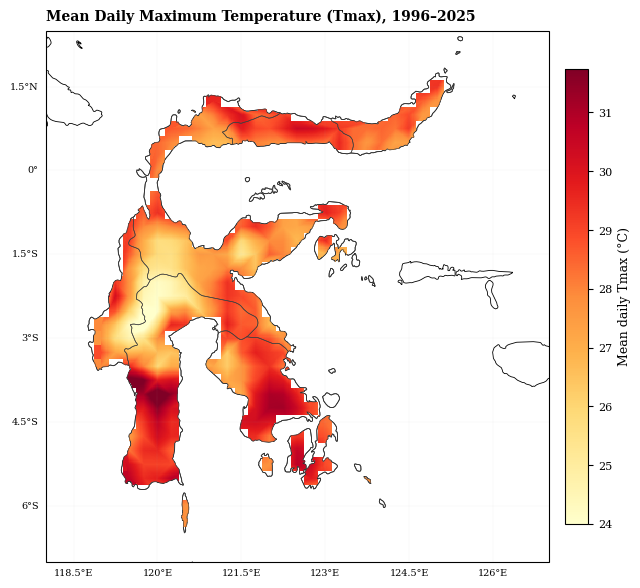

In [7]:
# ============================================================
# FIGURE 1 — MEAN DAILY TMAX CLIMATOLOGY
# ============================================================

sum_field = np.zeros((nlat, nlon), dtype=np.float64)
count_field = np.zeros((nlat, nlon), dtype=np.int64)

chunk = 366
for start in range(0, n_total_days, chunk):
    block = np.asarray(daily_tmax[start:start+chunk], dtype=np.float32)
    sum_field += np.nansum(block, axis=0)
    count_field += np.sum(np.isfinite(block), axis=0)

mean_daily_tmax = np.divide(
    sum_field, count_field,
    out=np.full_like(sum_field, np.nan, dtype=float),
    where=count_field > 0
)
mean_daily_tmax = masked(mean_daily_tmax)

vmin, vmax = robust_limits(mean_daily_tmax, low=1, high=99)

fig = plt.figure(figsize=(7.0, 7.2))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
mesh = draw_spatial_field(
        ax, mean_daily_tmax, cmap="YlOrRd", vmin=vmin, vmax=vmax,
    )
setup_map_ax(ax)
ax.set_title(
    f"Mean Daily Maximum Temperature (Tmax), {START_YEAR}–{END_YEAR}",
    fontweight="bold", loc="left", pad=7
)
cbar = fig.colorbar(mesh, ax=ax, orientation="vertical", fraction=0.042, pad=0.03)
cbar.set_label("Mean daily Tmax (°C)")

save_figure(fig, "FIG01_Mean_Daily_Tmax_Sulawesi_1996_2025")
plt.show()
plt.close(fig)


## 8. Threshold kalender-harian P90 dan P95

Untuk setiap hari kalender, threshold dihitung dari **centered 15-day window**: tanggal target + 7 hari sebelum + 7 hari sesudah, digabung untuk seluruh tahun. Tanggal 29 Februari tidak punya day-of-year tersendiri; saat threshold harian dibutuhkan, nilainya diinterpolasi dari 28 Februari dan 1 Maret.


In [8]:
# ============================================================
# 8. THRESHOLD P90 / P95 — 15-DAY CENTERED WINDOW
# ============================================================

def noleap_day_index(datetime_index):
    out = np.full(len(datetime_index), -1, dtype=np.int16)
    for i, ts in enumerate(datetime_index):
        if ts.month == 2 and ts.day == 29:
            continue
        doy = ts.dayofyear - 1
        if ts.is_leap_year and ts.month > 2:
            doy -= 1
        out[i] = doy
    return out


def build_calendar_threshold(daily_data, dates, percentile, window_days=15):
    if window_days % 2 == 0:
        raise ValueError("window_days harus ganjil.")
    half = window_days // 2
    dti = pd.DatetimeIndex(dates.astype("datetime64[ns]"))
    noleap = noleap_day_index(dti)
    threshold = np.full((365, daily_data.shape[1], daily_data.shape[2]), np.nan, np.float32)

    for target in range(365):
        valid = noleap >= 0
        distance = np.abs(noleap - target)
        distance = np.minimum(distance, 365 - distance)
        selected = np.where(valid & (distance <= half))[0]

        # Untuk 1996–2025 dan window 15 hari, target normal = 15 × 30 = 450 sampel/grid.
        block = np.asarray(daily_data[selected], dtype=np.float32)
        threshold[target] = np.nanpercentile(block, percentile, axis=0).astype(np.float32)
        del block
        if (target + 1) % 50 == 0 or target in [0, 364]:
            print(f"P{percentile}: {target+1}/365")
    return threshold


def threshold_for_dates(threshold_clim, dates_subset):
    dti = pd.DatetimeIndex(dates_subset.astype("datetime64[ns]"))
    idx = noleap_day_index(dti)
    out = np.full((len(dates_subset), threshold_clim.shape[1], threshold_clim.shape[2]), np.nan, np.float32)
    regular = idx >= 0
    out[regular] = threshold_clim[idx[regular]]
    feb29 = idx < 0
    if np.any(feb29):
        out[feb29] = 0.5 * (threshold_clim[58] + threshold_clim[59])
    return out


threshold_cache = CACHE_DIR / f"calendar_thresholds_P90_P95_W{WINDOW_DAYS}_{START_YEAR}_{END_YEAR}.npz"
thresholds = {}

if threshold_cache.exists() and not REBUILD_THRESHOLDS:
    print("Memuat threshold cache:", threshold_cache)
    z = np.load(threshold_cache)
    thresholds["P90"] = z["P90"]
    thresholds["P95"] = z["P95"]
else:
    for p in PERCENTILES:
        thresholds[f"P{p}"] = build_calendar_threshold(daily_tmax, dates, p, WINDOW_DAYS)
    np.savez_compressed(threshold_cache, P90=thresholds["P90"], P95=thresholds["P95"])

for key, arr in thresholds.items():
    print(
        key, "| shape", arr.shape,
        "| mean", round(float(np.nanmean(arr)), 3),
        "| min", round(float(np.nanmin(arr)), 3),
        "| max", round(float(np.nanmax(arr)), 3)
    )


Memuat threshold cache: D:\MERLI\data\TMAX\HEATWAVE_JOURNAL_OUTPUT\cache\calendar_thresholds_P90_P95_W15_1996_2025.npz
P90 | shape (365, 57, 45) | mean 29.679 | min 23.799 | max 37.229
P95 | shape (365, 57, 45) | mean 30.07 | min 24.189 | max 37.679


## 9. Figure 2 — Perbandingan P90 dan P95

Panel (a) dan (b) memakai skala warna yang sama. Panel (c) menunjukkan berapa °C P95 lebih tinggi daripada P90 secara rata-rata sepanjang kalender.


Tersimpan: D:\MERLI\data\TMAX\HEATWAVE_JOURNAL_OUTPUT\plots\FIG02_P90_P95_Threshold_Comparison.png


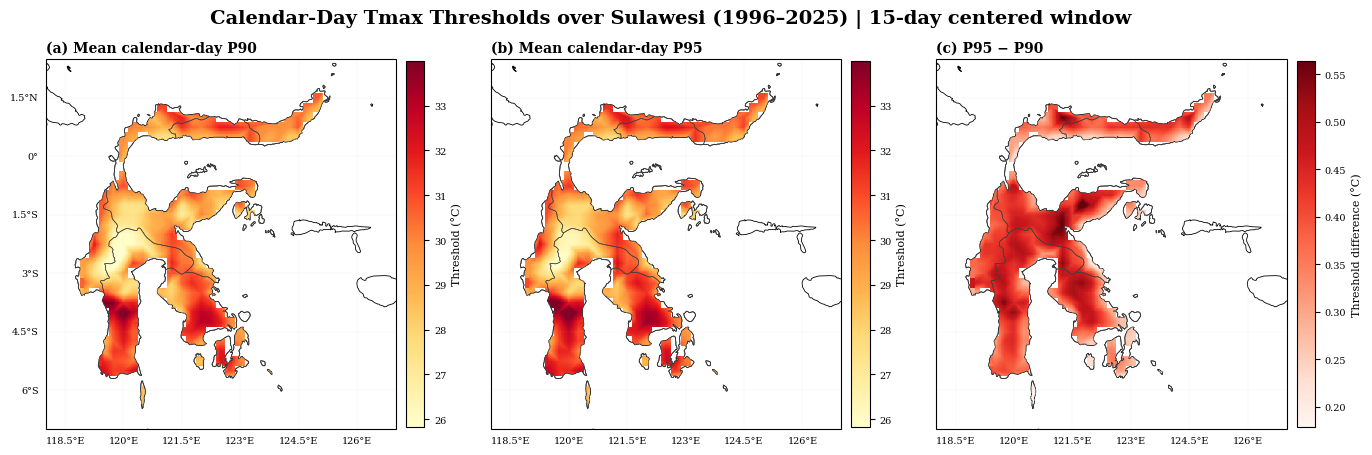

In [9]:
# ============================================================
# FIGURE 2 — P90 vs P95 THRESHOLD CLIMATOLOGY
# ============================================================

p90_mean = masked(np.nanmean(thresholds["P90"], axis=0))
p95_mean = masked(np.nanmean(thresholds["P95"], axis=0))
delta_95_90 = masked(p95_mean - p90_mean)

thr_vmin, thr_vmax = robust_limits([p90_mean, p95_mean], low=1, high=99)
d_vmin, d_vmax = robust_limits(delta_95_90, low=1, high=99)

fig = plt.figure(figsize=(14.0, 5.0))
gs = fig.add_gridspec(1, 3, wspace=0.12, left=0.04, right=0.96, bottom=0.12, top=0.86)

panels = [
    (p90_mean, "(a) Mean calendar-day P90", "YlOrRd", thr_vmin, thr_vmax, "Threshold (°C)"),
    (p95_mean, "(b) Mean calendar-day P95", "YlOrRd", thr_vmin, thr_vmax, "Threshold (°C)"),
    (delta_95_90, "(c) P95 − P90", "Reds", d_vmin, d_vmax, "Threshold difference (°C)"),
]

for i, (z, title, cmap, vmin, vmax, label) in enumerate(panels):
    ax = fig.add_subplot(gs[0, i], projection=ccrs.PlateCarree())
    mesh = draw_spatial_field(
        ax, z, cmap=cmap, vmin=vmin, vmax=vmax,
    )
    setup_map_ax(ax, left_labels=(i == 0), bottom_labels=True)
    ax.set_title(title, fontweight="bold", loc="left", pad=5)
    cb = fig.colorbar(mesh, ax=ax, orientation="vertical", fraction=0.046, pad=0.025)
    cb.set_label(label, fontsize=8)
    cb.ax.tick_params(labelsize=7)

fig.suptitle(
    f"Calendar-Day Tmax Thresholds over Sulawesi ({START_YEAR}–{END_YEAR}) | {WINDOW_DAYS}-day centered window",
    fontweight="bold", y=0.96
)

save_figure(fig, "FIG02_P90_P95_Threshold_Comparison")
plt.show()
plt.close(fig)


## 10. Deteksi event heatwave dan lima karakteristik

Notebook menghitung semua enam skenario. Definisi tahunannya:

- `HWN`: jumlah event.
- `HWF`: total heatwave days.
- `HWD`: event terpanjang.
- `HWA_abs`: Tmax maksimum pada heatwave days.
- `HWM_abs`: Tmax rata-rata pada heatwave days.
- `HWA_excess`: maksimum `Tmax − threshold` pada heatwave days.
- `HWM_excess`: rata-rata `Tmax − threshold` pada heatwave days.

Figure utama memilih `HWA_abs/HWM_abs` jika `INTENSITY_MODE="absolute"`, tetapi data excess tetap ada buat analisis tambahan.


In [10]:
# ============================================================
# 10. EVENT DETECTION + ANNUAL METRICS
# ============================================================

def compute_event_mask(exceed, min_duration):
    """Tandai seluruh hari yang termasuk run True dengan panjang >= min_duration."""
    ntime = exceed.shape[0]
    run_end = np.zeros(exceed.shape, dtype=np.int16)
    run = np.zeros(exceed.shape[1:], dtype=np.int16)

    for t in range(ntime):
        run = np.where(exceed[t], run + 1, 0).astype(np.int16)
        run_end[t] = run

    event_mask = np.zeros(exceed.shape, dtype=bool)
    run = np.zeros(exceed.shape[1:], dtype=np.int16)
    for t in range(ntime - 1, -1, -1):
        run = np.where(exceed[t], run + 1, 0).astype(np.int16)
        event_mask[t] = exceed[t] & ((run_end[t] + run - 1) >= min_duration)

    return event_mask, run_end


def compute_year_metrics(data_year, threshold_year, min_duration):
    exceed = np.isfinite(data_year) & np.isfinite(threshold_year) & (data_year > threshold_year)
    event_mask, run_end = compute_event_mask(exceed, min_duration)

    hwn = np.sum(run_end == min_duration, axis=0).astype(np.float32)
    hwf = np.sum(event_mask, axis=0).astype(np.float32)
    hwd = np.max(np.where(event_mask, run_end, 0), axis=0).astype(np.float32)

    excess = data_year - threshold_year
    excess_event = np.where(event_mask, excess, np.nan)
    absolute_event = np.where(event_mask, data_year, np.nan)

    hwa_excess = np.nanmax(excess_event, axis=0).astype(np.float32)
    hwm_excess = np.nanmean(excess_event, axis=0).astype(np.float32)
    hwa_abs = np.nanmax(absolute_event, axis=0).astype(np.float32)
    hwm_abs = np.nanmean(absolute_event, axis=0).astype(np.float32)

    no_event = hwf == 0
    for a in [hwa_excess, hwm_excess, hwa_abs, hwm_abs]:
        a[no_event] = np.nan

    # Pastikan luar Sulawesi tetap NaN pada semua metrics.
    for a in [hwn, hwf, hwd, hwa_excess, hwm_excess, hwa_abs, hwm_abs]:
        a[~sulawesi_mask] = np.nan

    return {
        "HWN": hwn,
        "HWF": hwf,
        "HWD": hwd,
        "HWA_excess": hwa_excess,
        "HWM_excess": hwm_excess,
        "HWA_abs": hwa_abs,
        "HWM_abs": hwm_abs,
    }


date_index = pd.DatetimeIndex(dates.astype("datetime64[ns]"))
year_idx = {int(y): np.where(date_index.year == int(y))[0] for y in YEARS}
METRICS = ["HWN", "HWF", "HWD", "HWA_excess", "HWM_excess", "HWA_abs", "HWM_abs"]

scenario_results = {}
for scenario in SCENARIOS:
    p = int(re.search(r"P(\d+)", scenario).group(1))
    d = int(re.search(r"D(\d+)", scenario).group(1))
    cache_file = CACHE_DIR / f"metrics_{scenario}_W{WINDOW_DAYS}_{START_YEAR}_{END_YEAR}.npz"

    if cache_file.exists() and not RECALCULATE_METRICS:
        loaded = np.load(cache_file)
        scenario_results[scenario] = {metric: loaded[metric] for metric in METRICS}
        print("Loaded:", scenario)
        continue

    annual = {
        metric: np.full((len(YEARS), nlat, nlon), np.nan, dtype=np.float32)
        for metric in METRICS
    }
    threshold_clim = thresholds[f"P{p}"]

    print(f"\nMenghitung {scenario} ...")
    for yi, year in enumerate(YEARS):
        idx = year_idx[int(year)]
        data_year = np.asarray(daily_tmax[idx], dtype=np.float32)
        thr_year = threshold_for_dates(threshold_clim, dates[idx])
        result = compute_year_metrics(data_year, thr_year, d)
        for metric in METRICS:
            annual[metric][yi] = result[metric]
        if (yi + 1) % 5 == 0 or yi in [0, len(YEARS)-1]:
            print(f"  {int(year)} selesai ({yi+1}/{len(YEARS)})")
        del data_year, thr_year, result
        gc.collect()

    scenario_results[scenario] = annual
    np.savez_compressed(cache_file, years=YEARS, **annual)
    print("Saved:", cache_file)


Loaded: P90_D3
Loaded: P90_D4
Loaded: P90_D5
Loaded: P95_D3
Loaded: P95_D4
Loaded: P95_D5


## 11. Area-weighted annual mean dan quality control

Rata-rata Sulawesi diberi bobot `cos(latitude)`, bukan mean grid mentah. Ini penting supaya grid pada lintang yang berbeda tidak diperlakukan seolah luasnya identik.


In [11]:
# ============================================================
# 11. AREA-WEIGHTED MEAN + QC
# ============================================================

area_weights = np.cos(np.deg2rad(lat2d))
area_weights = np.where(sulawesi_mask, area_weights, np.nan)


def weighted_grid_mean(field):
    field = np.asarray(field, dtype=float)
    if field.ndim == 2:
        valid = np.isfinite(field) & np.isfinite(area_weights)
        if not np.any(valid):
            return np.nan
        return float(np.nansum(field[valid] * area_weights[valid]) / np.nansum(area_weights[valid]))
    if field.ndim == 3:
        return np.asarray([weighted_grid_mean(field[i]) for i in range(field.shape[0])])
    raise ValueError("field harus 2-D atau 3-D")


rows = []
qc_rows = []
for scenario, annual in scenario_results.items():
    d = int(re.search(r"D(\d+)", scenario).group(1))
    for yi, year in enumerate(YEARS):
        row = {"scenario": scenario, "year": int(year)}
        for metric in METRICS:
            row[metric] = weighted_grid_mean(annual[metric][yi])
        rows.append(row)

        hwn = annual["HWN"][yi]
        hwf = annual["HWF"][yi]
        hwd = annual["HWD"][yi]
        valid = np.isfinite(hwn)
        qc_rows.append({
            "scenario": scenario,
            "year": int(year),
            "HWF_ge_D_times_HWN": bool(np.all(hwf[valid] >= d * hwn[valid])),
            "HWD_consistent": bool(np.all(((hwn[valid] == 0) & (hwd[valid] == 0)) | ((hwn[valid] > 0) & (hwd[valid] >= d)))),
        })

annual_df = pd.DataFrame(rows)
qc_df = pd.DataFrame(qc_rows)

print("QC HWF >= D×HWN:", qc_df["HWF_ge_D_times_HWN"].all())
print("QC HWD          :", qc_df["HWD_consistent"].all())
display(annual_df.head())


QC HWF >= D×HWN: True
QC HWD          : True


,scenario,year,HWN,HWF,HWD,HWA_excess,HWM_excess,HWA_abs,HWM_abs
0,P90_D3,1996,0.181576,0.610777,0.482944,0.720326,0.380481,30.537350,30.135516
1,P90_D3,1997,1.462426,6.511711,2.892907,1.364633,0.627902,31.435452,30.476596
2,P90_D3,1998,1.656019,7.302472,2.829898,1.204604,0.542236,31.104115,30.346298
3,P90_D3,1999,0.066127,0.297679,0.297679,0.661653,0.376516,30.686428,30.408019
4,P90_D3,2000,0.491717,1.673379,1.446035,0.786932,0.460609,30.737552,30.353988


## 12. Figure 3 — Sensitivitas spasial P90/P95 × 3/4/5 hari

Untuk sensitivity map dipakai **HWF (days/year)** karena HWF paling gampang dibaca secara spasial: makin ketat threshold atau makin panjang minimum duration, heatwave days seharusnya umumnya makin sedikit. Semua enam panel memakai **satu skala warna bersama**, jadi perbandingan tidak tipu-tipu colorbar.


Tersimpan: D:\MERLI\data\TMAX\HEATWAVE_JOURNAL_OUTPUT\plots\FIG03_Sensitivity_Spatial_HWF_P90_P95_D3_D4_D5.png


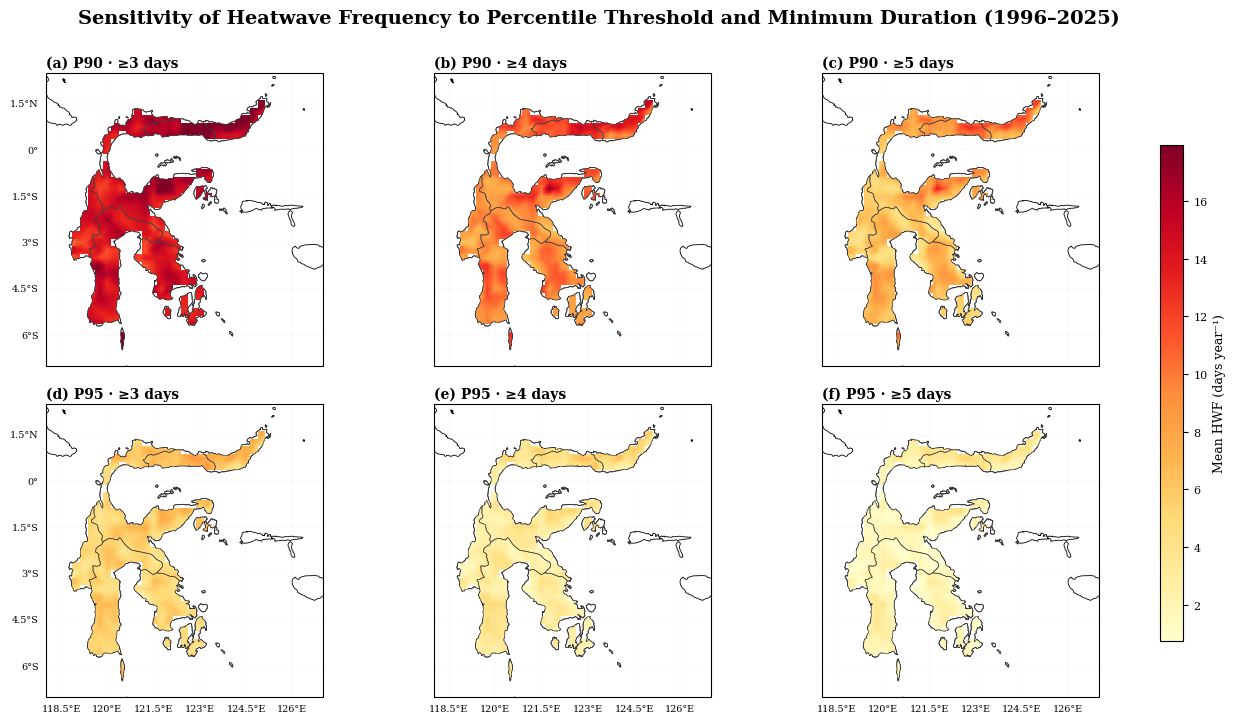

In [12]:
# ============================================================
# FIGURE 3 — SENSITIVITY SPATIAL HWF: P90/P95 × D3/D4/D5
# ============================================================

hwf_maps = {
    scenario: masked(np.nanmean(scenario_results[scenario]["HWF"], axis=0))
    for scenario in SCENARIOS
}
svmin, svmax = robust_limits(list(hwf_maps.values()), low=1, high=99)

fig = plt.figure(figsize=(13.2, 8.0))
gs = fig.add_gridspec(2, 3, wspace=0.08, hspace=0.13, left=0.05, right=0.91, bottom=0.10, top=0.88)

mesh = None
for i, scenario in enumerate(SCENARIOS):
    row, col = i // 3, i % 3
    ax = fig.add_subplot(gs[row, col], projection=ccrs.PlateCarree())
    mesh = draw_spatial_field(
        ax, hwf_maps[scenario], cmap="YlOrRd", vmin=svmin, vmax=svmax,
    )
    p = int(re.search(r"P(\d+)", scenario).group(1))
    d = int(re.search(r"D(\d+)", scenario).group(1))
    setup_map_ax(ax, left_labels=(col == 0), bottom_labels=(row == 1))
    ax.set_title(f"({chr(97+i)}) P{p} · ≥{d} days", fontweight="bold", loc="left", pad=4)

# Shared colorbar
cax = fig.add_axes([0.925, 0.17, 0.018, 0.62])
cb = fig.colorbar(mesh, cax=cax, orientation="vertical")
cb.set_label("Mean HWF (days year⁻¹)")

fig.suptitle(
    f"Sensitivity of Heatwave Frequency to Percentile Threshold and Minimum Duration ({START_YEAR}–{END_YEAR})",
    fontweight="bold", y=0.96
)

save_figure(fig, "FIG03_Sensitivity_Spatial_HWF_P90_P95_D3_D4_D5")
plt.show()
plt.close(fig)


## 13. Figure 4 — Sensitivitas time series lima karakteristik

Visual encoding dibuat konsisten: **warna = minimum duration**, sedangkan **linestyle = percentile**. Jadi P90 vs P95 dan D3/D4/D5 bisa dibaca tanpa bikin legenda jadi pasar malam.


Tersimpan: D:\MERLI\data\TMAX\HEATWAVE_JOURNAL_OUTPUT\plots\FIG04_Sensitivity_TimeSeries_All_Metrics.png


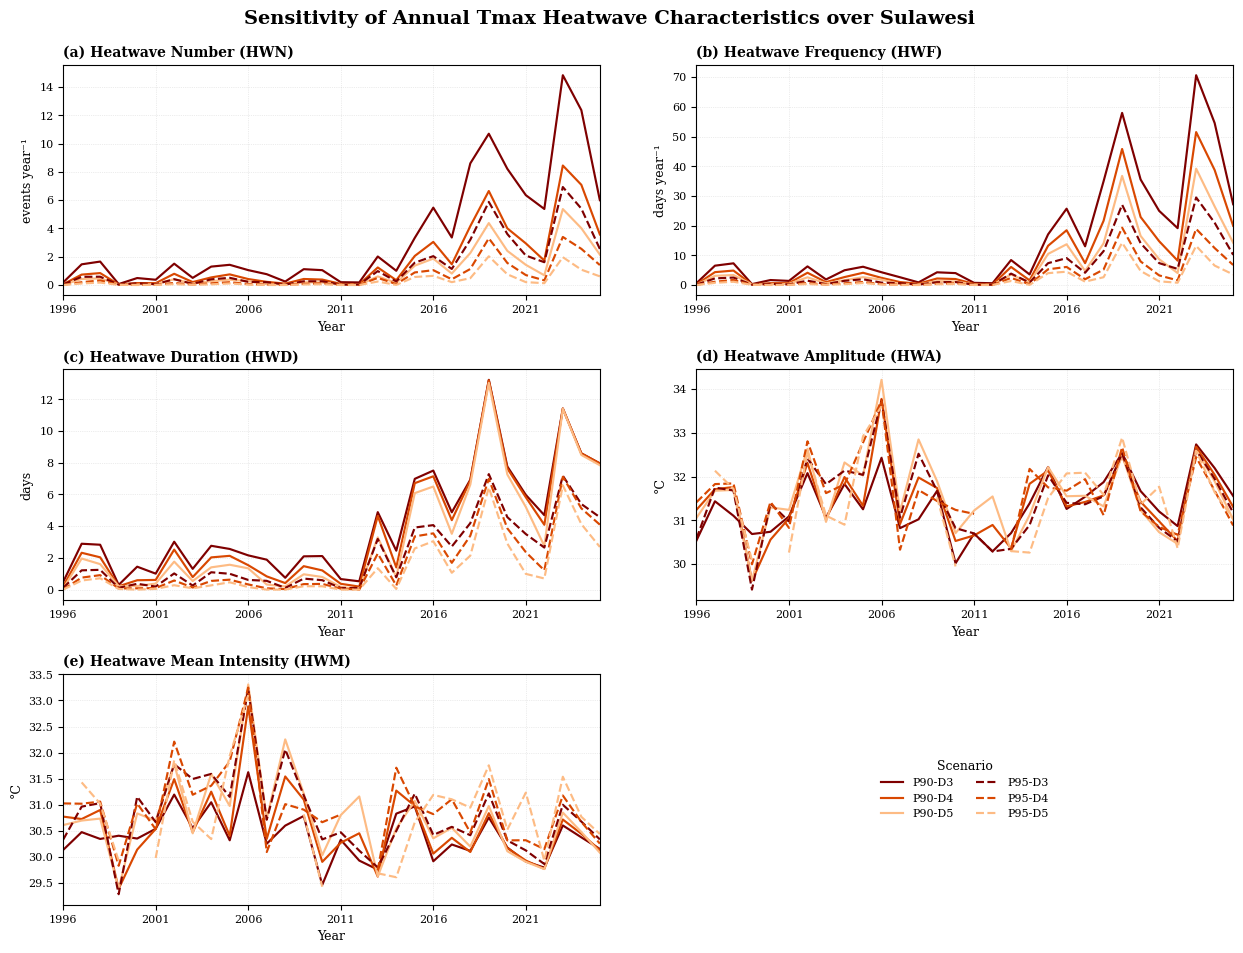

In [13]:
# ============================================================
# FIGURE 4 — SENSITIVITY TIME SERIES
# ============================================================

if INTENSITY_MODE == "absolute":
    hwa_metric, hwm_metric = "HWA_abs", "HWM_abs"
    intensity_unit = "°C"
else:
    hwa_metric, hwm_metric = "HWA_excess", "HWM_excess"
    intensity_unit = "°C above threshold"

plot_metrics = [
    ("HWN", "Heatwave Number (HWN)", "events year⁻¹"),
    ("HWF", "Heatwave Frequency (HWF)", "days year⁻¹"),
    ("HWD", "Heatwave Duration (HWD)", "days"),
    (hwa_metric, "Heatwave Amplitude (HWA)", intensity_unit),
    (hwm_metric, "Heatwave Mean Intensity (HWM)", intensity_unit),
]

duration_colors = {
    3: "#7f0000",
    4: "#d94801",
    5: "#fdbb84",
}
percentile_styles = {90: "-", 95: "--"}

fig = plt.figure(figsize=(13.0, 10.0))
gs = fig.add_gridspec(3, 2, hspace=0.32, wspace=0.18, left=0.08, right=0.98, bottom=0.07, top=0.91)

axes = []
for i, (metric, title, ylabel) in enumerate(plot_metrics):
    ax = fig.add_subplot(gs[i // 2, i % 2])
    axes.append(ax)
    for scenario in SCENARIOS:
        p = int(re.search(r"P(\d+)", scenario).group(1))
        d = int(re.search(r"D(\d+)", scenario).group(1))
        sub = annual_df[annual_df["scenario"] == scenario].sort_values("year")
        ax.plot(
            sub["year"], sub[metric],
            color=duration_colors[d], linestyle=percentile_styles[p],
            linewidth=1.55, label=f"P{p}-D{d}"
        )
    ax.set_title(f"({chr(97+i)}) {title}", fontweight="bold", loc="left")
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Year")
    ax.set_xlim(START_YEAR, END_YEAR)
    ax.set_xticks(np.arange(START_YEAR, END_YEAR + 1, 5))
    ax.grid(True, linestyle=":", linewidth=0.5, alpha=0.45)

# panel kosong untuk legend
ax_leg = fig.add_subplot(gs[2, 1])
ax_leg.axis("off")
handles, labels = axes[0].get_legend_handles_labels()
ax_leg.legend(handles, labels, loc="center", frameon=False, ncol=2, title="Scenario")

fig.suptitle(
    "Sensitivity of Annual Tmax Heatwave Characteristics over Sulawesi",
    fontweight="bold", y=0.965
)

save_figure(fig, "FIG04_Sensitivity_TimeSeries_All_Metrics")
plt.show()
plt.close(fig)


## 14. Figure 5 — Peta lima karakteristik heatwave

Figure utama mengikuti `MAIN_SCENARIO`. Kalau mau versi P95-D3, cukup ubah satu baris di konfigurasi: `MAIN_SCENARIO = "P95_D3"` lalu jalankan ulang bagian plot; cache metrics tidak perlu dihitung ulang selama sudah ada.


Tersimpan: D:\MERLI\data\TMAX\HEATWAVE_JOURNAL_OUTPUT\plots\FIG05_Spatial_Heatwave_Characteristics_P90_D3_absolute.png


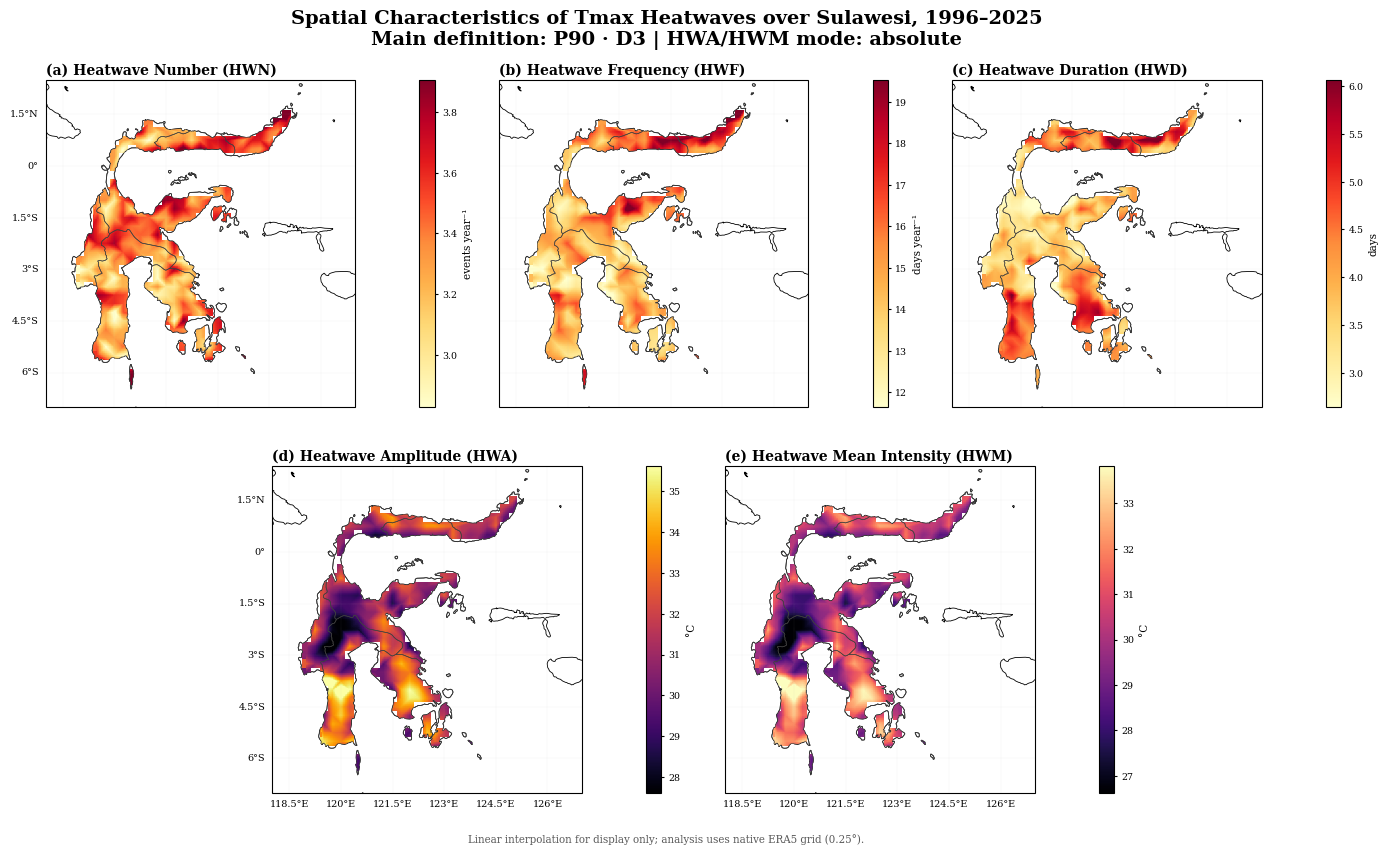

In [14]:
# ============================================================
# FIGURE 5 — SPATIAL CHARACTERISTICS: HWN, HWF, HWD, HWA, HWM
# ============================================================

main = scenario_results[MAIN_SCENARIO]

if INTENSITY_MODE == "absolute":
    hwa_key, hwm_key = "HWA_abs", "HWM_abs"
    hwa_label, hwm_label = "°C", "°C"
else:
    hwa_key, hwm_key = "HWA_excess", "HWM_excess"
    hwa_label, hwm_label = "°C above threshold", "°C above threshold"

map_specs = [
    ("HWN", "Heatwave Number (HWN)", "events year⁻¹", "YlOrRd"),
    ("HWF", "Heatwave Frequency (HWF)", "days year⁻¹", "YlOrRd"),
    ("HWD", "Heatwave Duration (HWD)", "days", "YlOrRd"),
    (hwa_key, "Heatwave Amplitude (HWA)", hwa_label, "inferno"),
    (hwm_key, "Heatwave Mean Intensity (HWM)", hwm_label, "magma"),
]

positions = [(0,0,2), (0,2,2), (0,4,2), (1,1,2), (1,3,2)]
fig = plt.figure(figsize=(14.5, 8.8))
outer = fig.add_gridspec(2, 6, hspace=0.18, wspace=0.05, left=0.035, right=0.965, bottom=0.07, top=0.88)

for i, ((metric, title, unit, cmap), pos) in enumerate(zip(map_specs, positions)):
    row, col, colspan = pos
    inner = outer[row, col:col+colspan].subgridspec(1, 2, width_ratios=[0.965, 0.035], wspace=0.05)
    ax = fig.add_subplot(inner[0, 0], projection=ccrs.PlateCarree())
    z = masked(np.nanmean(main[metric], axis=0))
    vmin, vmax = robust_limits(z, low=2, high=98)
    mesh = draw_spatial_field(
        ax, z, cmap=cmap, vmin=vmin, vmax=vmax,
    )
    setup_map_ax(ax, left_labels=(col <= 1), bottom_labels=(row == 1))
    ax.set_title(f"({chr(97+i)}) {title}", fontweight="bold", loc="left", pad=4)
    cax = fig.add_subplot(inner[0, 1])
    cb = fig.colorbar(mesh, cax=cax, orientation="vertical")
    cb.set_label(unit, fontsize=7.5)
    cb.ax.tick_params(labelsize=6.8, length=2)

fig.suptitle(
    f"Spatial Characteristics of Tmax Heatwaves over Sulawesi, {START_YEAR}–{END_YEAR}\n"
    f"Main definition: {MAIN_SCENARIO.replace('_', ' · ')} | HWA/HWM mode: {INTENSITY_MODE}",
    fontweight="bold", y=0.96
)

fig.text(0.50, 0.013, "Linear interpolation for display only; analysis uses native ERA5 grid (0.25°).",
         fontsize=7.4, ha="center", color="0.35")

save_figure(fig, f"FIG05_Spatial_Heatwave_Characteristics_{MAIN_SCENARIO}_{INTENSITY_MODE}")
plt.show()
plt.close(fig)


## 15. Figure 6 — Time series utama + Theil–Sen trend

Garis tipis = nilai tahunan; garis tebal = running mean 5 tahun; garis putus = tren Theil–Sen. Nilai `p` berasal dari Kendall tau dan dipakai sebagai indikator signifikansi tren monotonik.


Tersimpan: D:\MERLI\data\TMAX\HEATWAVE_JOURNAL_OUTPUT\plots\FIG06_Main_TimeSeries_TheilSen_P90_D3_absolute.png


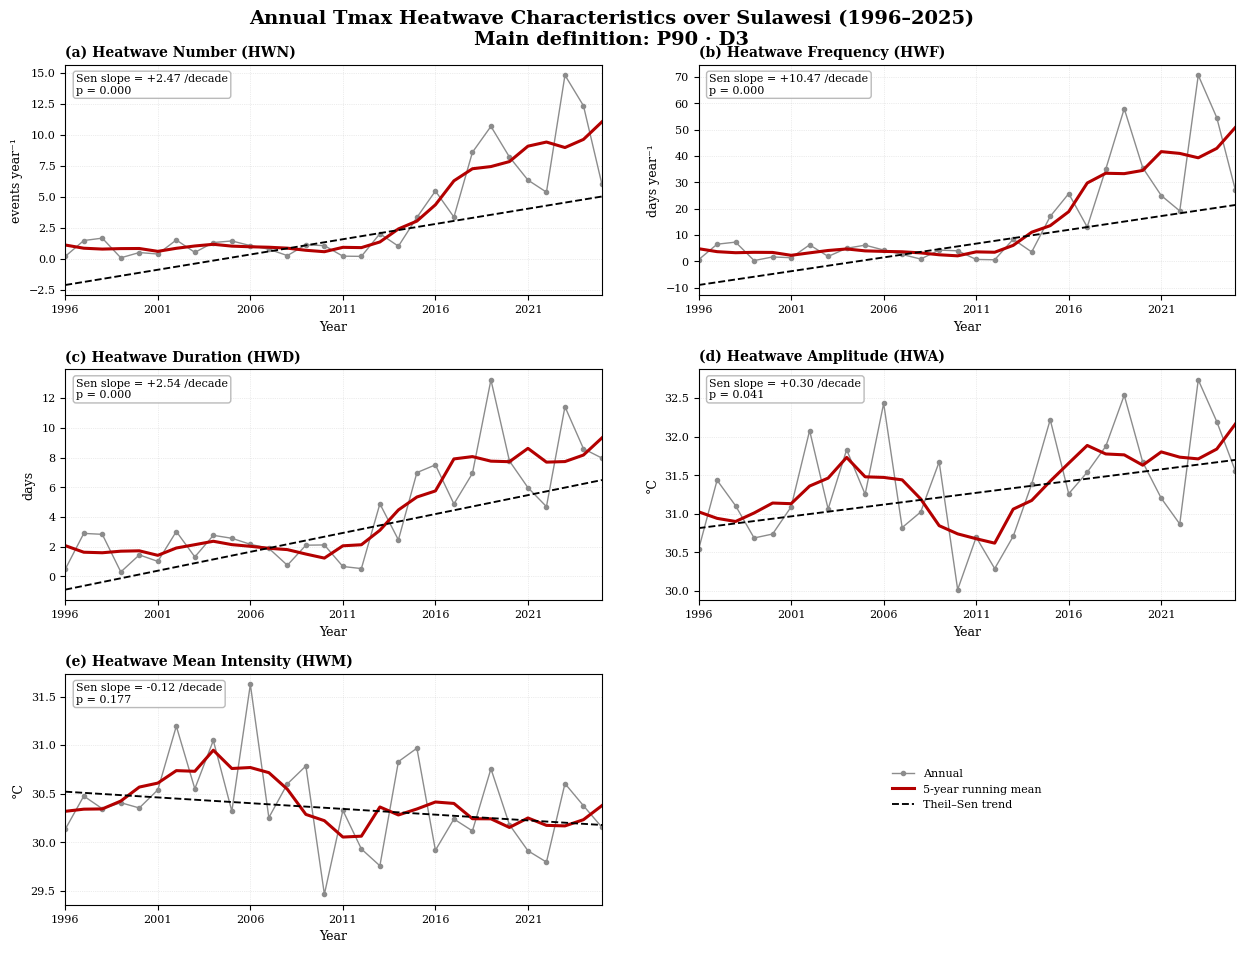

,metric,slope_per_decade,kendall_p
0,HWN,2.468348,0.000029
1,HWF,10.474116,0.000060
2,HWD,2.543320,0.000084
3,HWA_abs,0.304929,0.041219
4,HWM_abs,-0.118200,0.176636


In [15]:
# ============================================================
# FIGURE 6 — MAIN TIME SERIES + THEIL-SEN + KENDALL
# ============================================================

main_df = annual_df[annual_df["scenario"] == MAIN_SCENARIO].sort_values("year").copy()

main_metrics = [
    ("HWN", "Heatwave Number (HWN)", "events year⁻¹"),
    ("HWF", "Heatwave Frequency (HWF)", "days year⁻¹"),
    ("HWD", "Heatwave Duration (HWD)", "days"),
    (hwa_key, "Heatwave Amplitude (HWA)", hwa_label),
    (hwm_key, "Heatwave Mean Intensity (HWM)", hwm_label),
]

fig = plt.figure(figsize=(13.0, 10.0))
gs = fig.add_gridspec(3, 2, hspace=0.32, wspace=0.18, left=0.08, right=0.98, bottom=0.07, top=0.91)

trend_rows = []
for i, (metric, title, ylabel) in enumerate(main_metrics):
    ax = fig.add_subplot(gs[i // 2, i % 2])
    x = main_df["year"].to_numpy(dtype=float)
    y = main_df[metric].to_numpy(dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)

    ax.plot(x, y, color="0.55", linewidth=1.0, marker="o", markersize=3.0, label="Annual")
    rolling = pd.Series(y).rolling(5, center=True, min_periods=3).mean().to_numpy()
    ax.plot(x, rolling, color="#b30000", linewidth=2.2, label="5-year running mean")

    if valid.sum() >= 10:
        ts = theilslopes(y[valid], x[valid], alpha=0.95)
        trend = ts.intercept + ts.slope * x
        mk = kendalltau(x[valid], y[valid], nan_policy="omit")
        ax.plot(x, trend, color="black", linestyle="--", linewidth=1.35, label="Theil–Sen trend")
        slope_dec = ts.slope * 10.0
        pval = mk.pvalue
        ax.text(
            0.02, 0.96,
            f"Sen slope = {slope_dec:+.2f} /decade\np = {pval:.3f}",
            transform=ax.transAxes, ha="left", va="top", fontsize=8,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="0.7", alpha=0.9)
        )
        trend_rows.append({"metric": metric, "slope_per_decade": slope_dec, "kendall_p": pval})

    ax.set_title(f"({chr(97+i)}) {title}", fontweight="bold", loc="left")
    ax.set_xlabel("Year")
    ax.set_ylabel(ylabel)
    ax.set_xlim(START_YEAR, END_YEAR)
    ax.set_xticks(np.arange(START_YEAR, END_YEAR + 1, 5))
    ax.grid(True, linestyle=":", linewidth=0.5, alpha=0.45)

# Panel legend
ax_leg = fig.add_subplot(gs[2, 1])
ax_leg.axis("off")
handles, labels = fig.axes[0].get_legend_handles_labels()
ax_leg.legend(handles, labels, loc="center", frameon=False)

fig.suptitle(
    f"Annual Tmax Heatwave Characteristics over Sulawesi ({START_YEAR}–{END_YEAR})\nMain definition: {MAIN_SCENARIO.replace('_', ' · ')}",
    fontweight="bold", y=0.965
)

save_figure(fig, f"FIG06_Main_TimeSeries_TheilSen_{MAIN_SCENARIO}_{INTENSITY_MODE}")
plt.show()
plt.close(fig)

trend_summary_df = pd.DataFrame(trend_rows)
display(trend_summary_df)


## 16. Figure 7 — Perbandingan provinsi (opsional tapi berguna)

Bagian ini membandingkan evolusi heatwave di enam provinsi Sulawesi untuk definisi utama. Bukan wajib buat Bab Hasil, tapi berguna kalau dosen nanya “iya terus Sulsel sama Sulteng bedanya mana?”. Nah, biar nggak bengong.


Tersimpan: D:\MERLI\data\TMAX\HEATWAVE_JOURNAL_OUTPUT\plots\FIG07_Province_TimeSeries_P90_D3_absolute.png


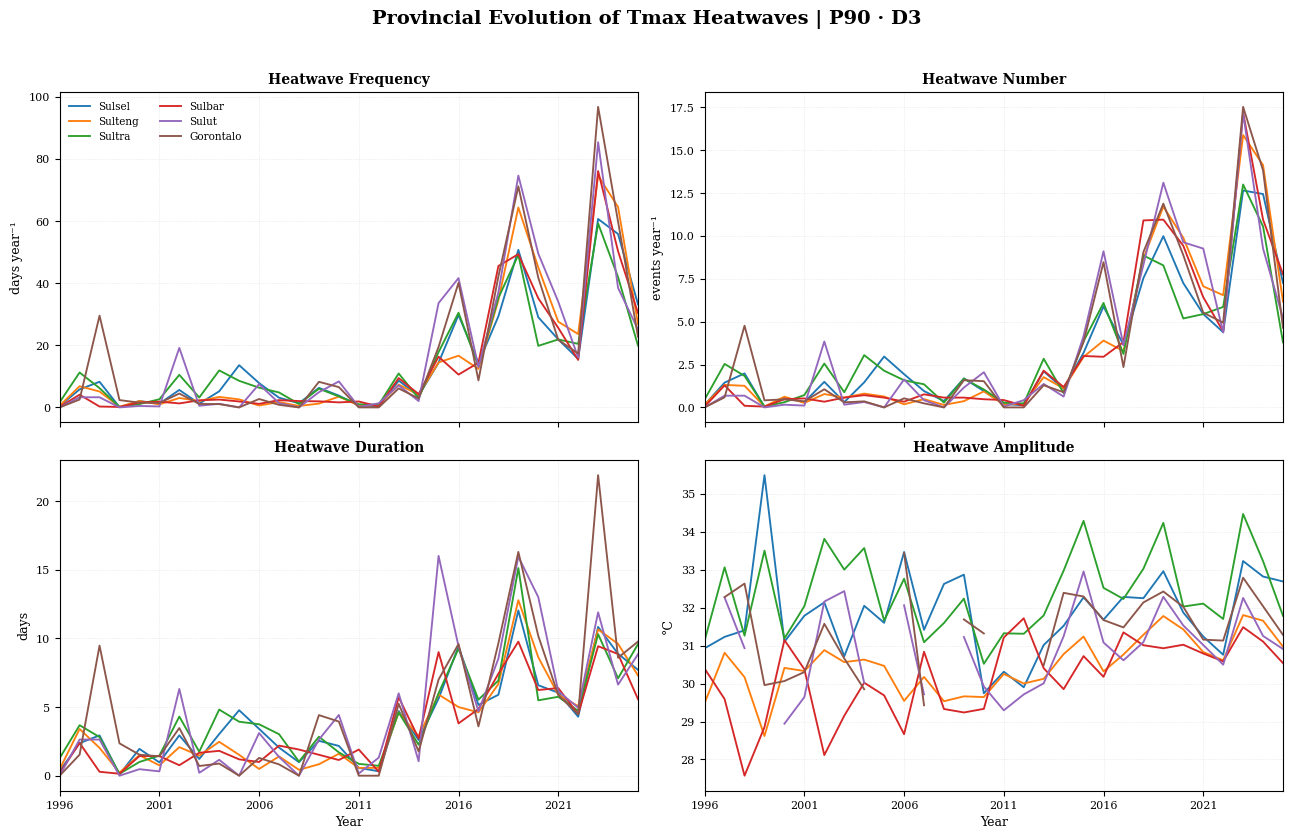

In [16]:
# ============================================================
# FIGURE 7 — PROVINCE TIME SERIES (MAIN SCENARIO)
# ============================================================


def regional_weighted_mean(field, region_mask):
    weights = np.where(region_mask, np.cos(np.deg2rad(lat2d)), np.nan)
    valid = np.isfinite(field) & np.isfinite(weights)
    if not np.any(valid):
        return np.nan
    return float(np.nansum(field[valid] * weights[valid]) / np.nansum(weights[valid]))

province_order = [
    "Sulawesi Selatan", "Sulawesi Tengah", "Sulawesi Tenggara",
    "Sulawesi Barat", "Sulawesi Utara", "Gorontalo"
]
province_short = {
    "Sulawesi Selatan": "Sulsel", "Sulawesi Tengah": "Sulteng",
    "Sulawesi Tenggara": "Sultra", "Sulawesi Barat": "Sulbar",
    "Sulawesi Utara": "Sulut", "Gorontalo": "Gorontalo"
}

regional_rows = []
for yi, year in enumerate(YEARS):
    for province in province_order:
        m = province_masks[province]
        for metric in ["HWN", "HWF", "HWD", hwa_key, hwm_key]:
            regional_rows.append({
                "year": int(year),
                "region": province,
                "metric": metric,
                "value": regional_weighted_mean(main[metric][yi], m),
            })
regional_df = pd.DataFrame(regional_rows)

province_metrics = [
    ("HWF", "Heatwave Frequency", "days year⁻¹"),
    ("HWN", "Heatwave Number", "events year⁻¹"),
    ("HWD", "Heatwave Duration", "days"),
    (hwa_key, "Heatwave Amplitude", hwa_label),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharex=True)
for ax, (metric, title, ylabel) in zip(axes.flat, province_metrics):
    for province in province_order:
        sub = regional_df[(regional_df["region"] == province) & (regional_df["metric"] == metric)].sort_values("year")
        ax.plot(sub["year"], sub["value"], linewidth=1.35, label=province_short[province])
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel(ylabel)
    ax.grid(True, linestyle=":", linewidth=0.5, alpha=0.4)
    ax.set_xlim(START_YEAR, END_YEAR)
    ax.set_xticks(np.arange(START_YEAR, END_YEAR + 1, 5))

axes[1,0].set_xlabel("Year")
axes[1,1].set_xlabel("Year")
axes[0,0].legend(ncol=2, frameon=False, fontsize=7.5)
fig.suptitle(f"Provincial Evolution of Tmax Heatwaves | {MAIN_SCENARIO.replace('_', ' · ')}", fontweight="bold", y=0.98)
fig.tight_layout(rect=[0, 0, 1, 0.96])

save_figure(fig, f"FIG07_Province_TimeSeries_{MAIN_SCENARIO}_{INTENSITY_MODE}")
plt.show()
plt.close(fig)


## 17. Ringkasan sensitivity dalam tabel + ekspor Excel

Selain plot, notebook menyimpan tabel annual mean, summary sensitivitas, trend, QC, threshold summary, dan regional series. Jadi kalau nanti bikin tabel skripsi, nggak usah ngorek angka dari gambar kayak arkeolog.


In [17]:
# ============================================================
# 17. SUMMARY TABLE + EXPORT
# ============================================================

summary_rows = []
for scenario in SCENARIOS:
    sub = annual_df[annual_df["scenario"] == scenario]
    p = int(re.search(r"P(\d+)", scenario).group(1))
    d = int(re.search(r"D(\d+)", scenario).group(1))
    summary_rows.append({
        "scenario": scenario,
        "percentile": p,
        "min_duration_days": d,
        "HWN_mean": sub["HWN"].mean(),
        "HWF_mean_days_per_year": sub["HWF"].mean(),
        "HWD_mean_days": sub["HWD"].mean(),
        "HWA_abs_mean_C": sub["HWA_abs"].mean(),
        "HWM_abs_mean_C": sub["HWM_abs"].mean(),
        "HWA_excess_mean_C": sub["HWA_excess"].mean(),
        "HWM_excess_mean_C": sub["HWM_excess"].mean(),
    })

sensitivity_summary_df = pd.DataFrame(summary_rows)
threshold_summary_df = pd.DataFrame([
    {
        "threshold": key,
        "mean_C": float(np.nanmean(arr)),
        "min_C": float(np.nanmin(arr)),
        "max_C": float(np.nanmax(arr)),
    }
    for key, arr in thresholds.items()
])

display(sensitivity_summary_df)

annual_csv = RESULT_DIR / "Annual_Heatwave_Metrics_All_Scenarios.csv"
annual_df.to_csv(annual_csv, index=False)

excel_path = RESULT_DIR / "TMAX_Heatwave_Journal_Combined_1996_2025.xlsx"
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    annual_df.to_excel(writer, sheet_name="Annual_Metrics", index=False)
    sensitivity_summary_df.to_excel(writer, sheet_name="Sensitivity_Summary", index=False)
    threshold_summary_df.to_excel(writer, sheet_name="Threshold_Summary", index=False)
    qc_df.to_excel(writer, sheet_name="Quality_Control", index=False)
    trend_summary_df.to_excel(writer, sheet_name="Trend_Main", index=False)
    regional_df.to_excel(writer, sheet_name="Regional_Main", index=False)
    qc_files.to_excel(writer, sheet_name="Input_Files", index=False)

print("CSV  :", annual_csv)
print("Excel:", excel_path)


,scenario,percentile,min_duration_days,HWN_mean,HWF_mean_days_per_year,HWD_mean_days,HWA_abs_mean_C,HWM_abs_mean_C,HWA_excess_mean_C,HWM_excess_mean_C
0,P90_D3,90,3,3.373339,14.908319,4.069168,31.350584,30.399793,1.243256,0.538408
1,P90_D4,90,4,1.754622,10.052169,3.645722,31.438139,30.567566,1.273684,0.580240
2,P90_D5,90,5,1.016445,7.099462,3.212776,31.555041,30.727743,1.330231,0.624996
3,P95_D3,95,3,1.369613,5.515880,2.113271,31.450196,30.801591,0.948214,0.458956
4,P95_D4,95,4,0.622768,3.275345,1.677422,31.563602,30.933163,1.034386,0.495274
5,P95_D5,95,5,0.319027,2.060380,1.257587,31.510163,30.830144,1.172265,0.562136


CSV  : D:\MERLI\data\TMAX\HEATWAVE_JOURNAL_OUTPUT\results\Annual_Heatwave_Metrics_All_Scenarios.csv
Excel: D:\MERLI\data\TMAX\HEATWAVE_JOURNAL_OUTPUT\results\TMAX_Heatwave_Journal_Combined_1996_2025.xlsx


## 18. Daftar output akhir

Setelah notebook selesai, folder `plots` berisi PNG 400 dpi dan PDF:

- `FIG01_Mean_Daily_Tmax_Sulawesi_1996_2025`
- `FIG02_P90_P95_Threshold_Comparison`
- `FIG03_Sensitivity_Spatial_HWF_P90_P95_D3_D4_D5`
- `FIG04_Sensitivity_TimeSeries_All_Metrics`
- `FIG05_Spatial_Heatwave_Characteristics_<MAIN_SCENARIO>_<mode>`
- `FIG06_Main_TimeSeries_TheilSen_<MAIN_SCENARIO>_<mode>`
- `FIG07_Province_TimeSeries_<MAIN_SCENARIO>_<mode>`

### Saran pemakaian untuk skripsi
- **Main result**: pakai Figure 1, 5, dan 6.
- **Sensitivity/robustness**: Figure 2, 3, dan 4.
- **Regional detail**: Figure 7 bila memang masuk tujuan penelitian.

Kalau dosen memilih **P95-D3** sebagai definisi utama, ganti `MAIN_SCENARIO` saja. Semua enam skenario tetap sudah dihitung, jadi nggak perlu bikin notebook baru lagi. Satu notebook, beres. Jangan berkembang biak jadi 17 notebook lagi.


In [18]:
# ============================================================
# 18. FINAL OUTPUT CHECK
# ============================================================

print("=" * 72)
print("HEATWAVE JOURNAL-STYLE ANALYSIS SELESAI")
print("Output directory:", OUTPUT_DIR)
print("Main scenario   :", MAIN_SCENARIO)
print("Intensity mode  :", INTENSITY_MODE)
print("=" * 72)

print("\nPLOTS:")
for fp in sorted(PLOT_DIR.glob("FIG*")):
    print(" -", fp.name)

print("\nRESULTS:")
for fp in sorted(RESULT_DIR.glob("*")):
    print(" -", fp.name)


HEATWAVE JOURNAL-STYLE ANALYSIS SELESAI
Output directory: D:\MERLI\data\TMAX\HEATWAVE_JOURNAL_OUTPUT
Main scenario   : P90_D3
Intensity mode  : absolute

PLOTS:
 - FIG01_Mean_Daily_Tmax_Sulawesi_1996_2025.pdf
 - FIG01_Mean_Daily_Tmax_Sulawesi_1996_2025.png
 - FIG02_P90_P95_Threshold_Comparison.pdf
 - FIG02_P90_P95_Threshold_Comparison.png
 - FIG03_Sensitivity_Spatial_HWF_P90_P95_D3_D4_D5.pdf
 - FIG03_Sensitivity_Spatial_HWF_P90_P95_D3_D4_D5.png
 - FIG04_Sensitivity_TimeSeries_All_Metrics.pdf
 - FIG04_Sensitivity_TimeSeries_All_Metrics.png
 - FIG05_Spatial_Heatwave_Characteristics_P90_D3_absolute.pdf
 - FIG05_Spatial_Heatwave_Characteristics_P90_D3_absolute.png
 - FIG06_Main_TimeSeries_TheilSen_P90_D3_absolute.pdf
 - FIG06_Main_TimeSeries_TheilSen_P90_D3_absolute.png
 - FIG07_Province_TimeSeries_P90_D3_absolute.pdf
 - FIG07_Province_TimeSeries_P90_D3_absolute.png

RESULTS:
 - Annual_Heatwave_Metrics_All_Scenarios.csv
 - QC_input_files.csv
 - TMAX_Heatwave_Journal_Combined_1996_2025.xlsx